# TP4 â€” LangGraph: Stateful Agents, Human-in-the-Loop, LangSmith & MCP â€” **CORRECTION**
## Module 2IAiasd 9.7 â€” Agentic AI Â· IMT Mines AlÃ¨s

> ðŸ”‘ This file is the **reference solution**, run on the internship report indexed in `chroma_db/` (Kenza Mouktabil, VINCI Construction SI).  
> The student version has the same structure with `pass` placeholders in exercises.  
> âš ï¸ Kernel: **Python 3.12** (`venv-crew`, same as TP3).

**Duration:** ~1 hour (second half of the session, after TP3)
**Prerequisites:**
- TP1 â€” the ReAct loop (`bind_tools`, `ToolMessage`, safety limit)
- TP2 â€” the `chroma_db/` folder (your internship report index) is next to this notebook
- `ollama serve` is running, `qwen2.5:3b` and `nomic-embed-text` are pulled
- *Optional:* a free LangSmith account and API key (Section 4)

**Objective:** In TP3, CrewAI decided the control flow for you. Today you take it back.
**LangGraph** describes an agent as an explicit **graph**: nodes (functions), edges (transitions) and a shared **state**.
This gives you what production agents need: routing, persistence, **human approval before risky actions**, and observability.
We finish with **MCP**, the standard protocol to plug external tools into any agent.

---

### Structure

| # | Section | Concepts | Time |
|---|---------|----------|------|
| 1 | StateGraph basics | state, nodes, edges, **conditional edges** â€” a router | 12 min |
| 2 | Tool-calling agent as a graph | `MessagesState`, `ToolNode`, `tools_condition` â€” TP1's loop as a graph | 8 min |
| 3 | Human-in-the-loop | checkpointer, `thread_id`, `interrupt()`, `Command(resume=...)` | 15 min |
| 4 | Advanced LangSmith traces | run names, tags, metadata, `@traceable`, feedback, querying runs | 10 min |
| 5 | MCP â€” presentation & demo | host / client / server, FastMCP, `langchain-mcp-adapters` | 15 min |

### CrewAI vs LangGraph

| | CrewAI (TP3) | LangGraph (TP4) |
|---|---|---|
| Abstraction | roles, tasks, crew | nodes, edges, state |
| Control flow | implicit (sequential / hierarchical) | **explicit**, you draw it |
| Loops & branches | limited | any graph, including cycles |
| Persistence / pause | limited | built-in checkpointer, `interrupt()` |
| Best for | fast prototyping of role-based teams | production agents you must control and debug |

---
## Setup

In [10]:
%pip install -q langgraph langchain-ollama langchain-chroma chromadb langsmith langchain-mcp-adapters mcp

print("âœ… Dependencies installed")

Note: you may need to restart the kernel to use updated packages.
âœ… Dependencies installed


In [11]:
import os, sys, uuid, requests
from pathlib import Path
from typing import Literal, TypedDict
from pydantic import BaseModel, Field

from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool

from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

MODEL       = "qwen2.5:3b"
EMBED_MODEL = "nomic-embed-text"
CHROMA_DIR  = "./chroma_db"

try:
    r = requests.get("http://localhost:11434/api/tags", timeout=3)
    print(f"âœ… Ollama running | models: {[m['name'] for m in r.json().get('models', [])]}")
except Exception:
    print("âŒ Ollama not reachable â€” run: ollama serve")

llm        = ChatOllama(model=MODEL, temperature=0)
embeddings = OllamaEmbeddings(model=EMBED_MODEL)

# â”€â”€ Knowledge base from TP2 (with a demo fallback) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
if Path(CHROMA_DIR).exists():
    vectorstore = Chroma(collection_name="rapport_recursive", embedding_function=embeddings,
                         persist_directory=CHROMA_DIR)
    print(f"âœ… TP2 index loaded â€” {vectorstore._collection.count()} chunks")
else:
    print("âš ï¸  chroma_db/ not found â€” building a small demo index")
    SAMPLE = [
        ("Introduction. The internship took place at a mid-size industrial company. "
         "The objective was to automate the classification of customer support tickets.", 0),
        ("Methods. We compared a TF-IDF + logistic regression baseline with a fine-tuned BERT model. "
         "Class imbalance was handled with SMOTE.", 3),
        ("Results. The BERT model reached 87% accuracy versus 74% for the baseline. "
         "Processing time per ticket dropped from 4 minutes to 10 seconds.", 7),
        ("Difficulties and perspectives. Labelled data was scarce. Future work: active learning "
         "and deployment as an internal web service.", 9),
    ]
    vectorstore = Chroma.from_documents(
        [Document(page_content=t, metadata={"page": p}) for t, p in SAMPLE],
        embeddings, collection_name="demo_report")
    print("âœ… Demo index built")

âœ… Ollama running | models: ['nomic-embed-text:latest', 'qwen2.5:3b']
âœ… TP2 index loaded â€” 84 chunks


---
## Section 1 â€” StateGraph basics: a question router

| Concept | In LangGraph | Example below |
|---------|-------------|---------------|
| **State** | a `TypedDict` shared by all nodes | `question`, `category`, `answer` |
| **Node** | a Python function `state â†’ partial update (dict)` | `classify`, `answer_from_report` |
| **Edge** | a fixed transition `A â†’ B` | `answer_general â†’ END` |
| **Conditional edge** | a function `state â†’ name of the next node` | `route()` after `classify` |
| `START` / `END` | entry and exit points | |
| `compile()` | checks the graph and returns a runnable (`invoke`, `stream`) | |

```
                     â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”
        START â”€â”€â”€â”€â”€â–º â”‚ classify  â”‚   (LLM with structured output)
                     â””â”€â”€â”€â”€â”€â”¬â”€â”€â”€â”€â”€â”˜
                route(state)â”‚
             â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”´â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”
      "report"â”‚                             â”‚"general"
   â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â–¼â”€â”€â”€â”€â”€â”€â”€â”€â”€â”        â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â–¼â”€â”€â”€â”€â”€â”€â”€â”€â”
   â”‚ answer_from_report â”‚        â”‚  answer_general   â”‚
   â”‚  (RAG on ChromaDB) â”‚        â”‚  (LLM knowledge)  â”‚
   â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”¬â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜        â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”¬â”€â”€â”€â”€â”€â”€â”€â”€â”˜
              â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â–º END â—„â”€â”€â”€â”€â”€â”€â”€â”€â”˜
```

### 1.1 â€” State and nodes

In [12]:
class RouterState(TypedDict):
    question: str
    category: str
    answer: str


class Route(BaseModel):
    category: Literal["report", "general"] = Field(
        description="'report' if the question is about the student's internship (company, project, "
                    "methods, results), otherwise 'general'")


router_llm = llm.with_structured_output(Route)


def classify(state: RouterState) -> dict:
    decision = router_llm.invoke([
        SystemMessage("Classify the user's question."),
        HumanMessage(state["question"]),
    ])
    print(f"  [classify] â†’ {decision.category}")
    return {"category": decision.category}          # a node returns ONLY the keys it updates


def answer_from_report(state: RouterState) -> dict:
    docs = vectorstore.similarity_search(state["question"], k=4)
    context = "\n\n".join(f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs)
    answer = llm.invoke([
        SystemMessage("Answer only from the context. Cite page numbers. "
                      "If the answer is not in the context, say so."),
        HumanMessage(f"Context:\n{context}\n\nQuestion: {state['question']}"),
    ]).content
    return {"answer": answer}


def answer_general(state: RouterState) -> dict:
    answer = llm.invoke([
        SystemMessage("You are a helpful assistant. Answer in at most 5 sentences."),
        HumanMessage(state["question"]),
    ]).content
    return {"answer": answer}


def route(state: RouterState) -> Literal["answer_from_report", "answer_general"]:
    return "answer_from_report" if state["category"] == "report" else "answer_general"


print("âœ… State and nodes defined")

âœ… State and nodes defined


### 1.2 â€” Build, compile and draw the graph

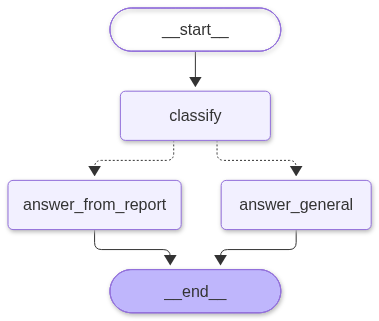

In [13]:
builder = StateGraph(RouterState)

builder.add_node("classify", classify)
builder.add_node("answer_from_report", answer_from_report)
builder.add_node("answer_general", answer_general)

builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route)   # next node chosen at run time
builder.add_edge("answer_from_report", END)
builder.add_edge("answer_general", END)

router_graph = builder.compile()


def draw(graph):
    """Display the graph as an image (needs internet) or fall back to Mermaid source."""
    try:
        from IPython.display import Image, display
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


draw(router_graph)

### 1.3 â€” Run it

`invoke` returns the **final state**. `stream(..., stream_mode="updates")` shows what each node wrote, step by step.

In [14]:
for q in ["What were the main results of my paper?",
          "What is the difference between precision and recall?"]:
    print(f"\nâ“ {q}")
    final_state = router_graph.invoke({"question": q})
    print(f"ðŸ’¬ {final_state['answer'][:400]}")


â“ What were the main results of my paper?
  [classify] â†’ report


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


ðŸ’¬ The main results of your paper were:

1. A comprehensive evaluation of modern SLMs on major Brazilian university entrance exams.
2. A granular analysis of model performance mapped across specific disciplines and cognitive capabilities.
3. An empirical assessment of the performance penalty incurred by replacing visual questions with textual descriptions.
4. A detailed cost-benefit analysis delineat

â“ What is the difference between precision and recall?
  [classify] â†’ report
ðŸ’¬ The provided context does not contain any information about precision and recall. Therefore, I cannot answer the question based on the given context.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


In [15]:
# Node-by-node view
for update in router_graph.stream({"question": "Which methods did I use during my experiment?"},
                                  stream_mode="updates"):
    for node, values in update.items():
        print(f"â”€â”€ {node} wrote: { {k: str(v)[:80] for k, v in values.items()} }")

  [classify] â†’ report
â”€â”€ classify wrote: {'category': 'report'}


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


â”€â”€ answer_from_report wrote: {'answer': 'Based on the context provided, the methods used during the experiment include:\n\n'}


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### 1.4 âœï¸ Exercise â€” Add an "off_topic" branch

Some questions should not be answered at all (e.g. *"Write my cover letter for me"*, *"Give me the exam answers"*).
Add a third category `"off_topic"` that is routed to a node `refuse` returning a polite refusal (no LLM call needed).

1. Create `Route3` with `Literal["report", "general", "off_topic"]` and a clear description.
2. Write `classify3`, `refuse` and `route3`.
3. Build `router_graph_v2`, draw it, test it with 3 questions (one per category).

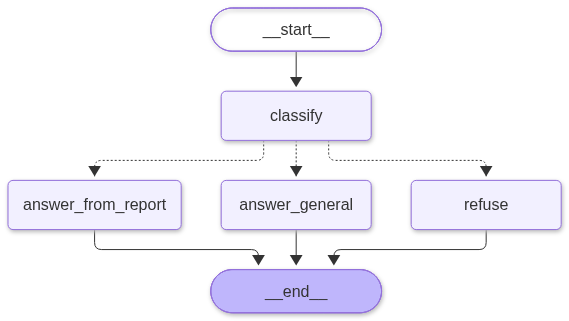


â“ What were the main results of my paper project?
  [classify3] â†’ report


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


ðŸ’¬ The main results of the paper project, as outlined in page 1 of the given context, are:

1. A comprehensive evaluation of modern SLMs on major Brazilian university entrance exams (ENEM and FUVEST).
2. A granular analysis of model performance mapped across specific disciplines and cognitive capabilit

â“ What is the difference between precision and recall?
  [classify3] â†’ general


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


ðŸ’¬ Precision measures the accuracy of positive predictions, while recall (also known as sensitivity) measures the ability of a model to find all the positive samples. In other words, precision answers the question "How many of the predicted positives are actually positives?" and recall asks "How many o

â“ Give me the answers to the final exam of the module.
  [classify3] â†’ off_topic
ðŸ’¬ Sorry, I can't help with this request. I can answer questions about your paper or general questions about the course.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


In [ ]:
class Route3(BaseModel):
    category: Literal["report", "general", "off_topic"] = Field(
        description="'report' if the question is about the student's paper (team, project, methods, results); "
                    "'off_topic' if the user asks the assistant to do graded or personal work for them "
                    "(write a cover letter, do homework, give exam answers) or anything unrelated to studies; "
                    "otherwise 'general'")


router_llm3 = llm.with_structured_output(Route3)

# With a 3B model, the Field description alone is not enough: "Give me the exam answers" was routed to "report".
# Explicit definitions + a few examples (few-shot) in the system prompt fix it.
CLASSIFY3_SYS = """Classify the user's message into exactly one category.
- off_topic: the user asks you to DO their graded or personal work, or to cheat
  (write a cover letter / CV / homework for them, give exam answers), or it is unrelated to studies.
- report: a question ABOUT the student's paper (team, project, methods, results, limitations).
- general: any other course or technical question (definitions, concepts).
Examples:
"Write my cover letter for me" -> off_topic
"Give me the exam answers" -> off_topic
"What were the results of my paper?" -> report
"What is overfitting?" -> general"""


def classify3(state: RouterState) -> dict:
    decision = router_llm3.invoke([
        SystemMessage(CLASSIFY3_SYS),
        HumanMessage(state["question"]),
    ])
    category = decision.category if decision else "general"     # fallback if the small model breaks the schema
    print(f"  [classify3] â†’ {category}")
    return {"category": category}


def refuse(state: RouterState) -> dict:
    # No LLM call: a fixed, predictable answer
    return {"answer": "Sorry, I can't help with this request. I can answer questions about your paper "
                      "or general questions about the course."}


def route3(state: RouterState) -> Literal["answer_from_report", "answer_general", "refuse"]:
    return {"report": "answer_from_report",
            "general": "answer_general",
            "off_topic": "refuse"}[state["category"]]


b = StateGraph(RouterState)
b.add_node("classify", classify3)
b.add_node("answer_from_report", answer_from_report)
b.add_node("answer_general", answer_general)
b.add_node("refuse", refuse)

b.add_edge(START, "classify")
b.add_conditional_edges("classify", route3)
b.add_edge("answer_from_report", END)
b.add_edge("answer_general", END)
b.add_edge("refuse", END)

router_graph_v2 = b.compile()
draw(router_graph_v2)

for q in ["What were the main results of my paper project?",            # â†’ report
          "What is the difference between precision and recall?",       # â†’ general
          "Give me the answers to the final exam of the module."]:       # â†’ off_topic
    print(f"\nâ“ {q}")
    print(f"ðŸ’¬ {router_graph_v2.invoke({'question': q})['answer'][:300]}")


---
## Section 2 â€” The ReAct agent as a graph

Remember the `while True` loop of TP1? It is a graph with **two nodes and a cycle**:

```
   START â”€â”€â–º agent â”€â”€â”€â”€ tool_calls? â”€â”€ no â”€â”€â–º END
               â–²            â”‚ yes
               â”‚            â–¼
               â””â”€â”€â”€â”€â”€â”€â”€â”€ tools          (ToolNode executes the calls, returns ToolMessages)
```

| TP1 (hand-written) | LangGraph |
|--------------------|-----------|
| `messages` list | `MessagesState` (with an *append* reducer) |
| `llm_with_tools.invoke(messages)` | node `agent` |
| `for call in response.tool_calls: ...` | `ToolNode(tools)` |
| `if not response.tool_calls: break` | `tools_condition` (conditional edge) |
| `max_steps` | `recursion_limit` in the config |

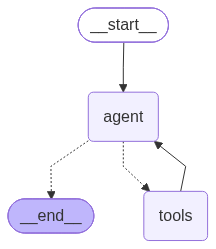

In [18]:
@tool
def search_paper(query: str) -> str:
    """Search the student's paper. Returns the 4 most relevant passages with page numbers.
    Use short, specific queries such as 'project objectives' or 'results accuracy'."""
    docs = vectorstore.similarity_search(query, k=4)
    return "\n\n".join(f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs) or "No passage found."


@tool
def word_count(text: str) -> int:
    """Count the number of words in a text."""
    return len(text.split())


AGENT_SYSTEM = ("You are an assistant for an engineering student. Use the tools when needed. "
                "Call one tool at a time. Never create information about the experiment: search the paper.")


def build_agent(tools, checkpointer=None):
    """ReAct agent as a LangGraph graph: agent â‡„ tools."""
    model = llm.bind_tools(tools)

    def agent(state: MessagesState) -> dict:
        response = model.invoke([SystemMessage(AGENT_SYSTEM)] + state["messages"])
        return {"messages": [response]}          # appended, not replaced (reducer of MessagesState)

    b = StateGraph(MessagesState)
    b.add_node("agent", agent)
    b.add_node("tools", ToolNode(tools))
    b.add_edge(START, "agent")
    b.add_conditional_edges("agent", tools_condition)   # â†’ "tools" or END
    b.add_edge("tools", "agent")                         # the cycle
    return b.compile(checkpointer=checkpointer)


agent_graph = build_agent([search_paper, word_count])
draw(agent_graph)

In [19]:
out = agent_graph.invoke(
    {"messages": [HumanMessage("What was the main objective of my paper?")]},
    config={"recursion_limit": 10},     # safety limit (TP1's max_steps)
)

for m in out["messages"]:
    m.pretty_print()

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


================================ Human Message =================================

What was the main objective of my paper?
================================== Ai Message ==================================
Tool Calls:
  search_paper (e3f1be09-c90a-4e78-8f96-d36bf6c4b393)
 Call ID: e3f1be09-c90a-4e78-8f96-d36bf6c4b393
  Args:
    query: project objectives
================================= Tool Message =================================
Name: search_paper

[page 1] In summary, our main contributions are: (1) a comprehensive evaluation of mod-
ern SLMs on major Brazilian university entrance exams; (2) a granular analysis of model
performance mapped across specific disciplines and cognitive capabilities; (3) an empir-
ical assessment of the performance penalty incurred by replacing visual questions with
textual descriptions; and (4) a detailed cost-benefit analysis delineating the Pareto frontier

[page 10] Nguyen, C., Shen, X., Aponte, R., et al. (2025). A survey on small language models.
In

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


---
## Section 3 â€” Human-in-the-loop (HITL)

Some actions are **irreversible**: sending an email, writing to a database, paying, deleting files.
An agent should not do them alone. LangGraph can **pause** the graph, ask a human, and **resume** later â€” even hours later.

Three ingredients:

| Ingredient | Role |
|-----------|------|
| **Checkpointer** (`MemorySaver`) | saves the state after every step |
| **`thread_id`** in the config | identifies one conversation / one execution |
| **`interrupt(payload)`** | pauses the graph and sends `payload` to the caller |
| **`Command(resume=value)`** | resumes the graph; `interrupt()` returns `value` |

```
  invoke(question) â”€â”€â–º agent â”€â”€â–º tools â”€â”€â–º send_email â”€â”€â–º interrupt({...})  â¸  state saved
                                                                â”‚
                                      caller sees result["__interrupt__"]
                                      human decides: {"approved": True}
                                                                â”‚
  invoke(Command(resume={"approved": True})) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜
                                      â”€â”€â–º send_email continues â”€â”€â–º agent â”€â”€â–º END
```

### 3.1 â€” A sensitive tool that asks for approval

In [20]:
SENT_EMAILS = []   # simulated outbox â€” no real email is ever sent


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an email to a recipient. Requires human approval before sending."""
    decision = interrupt({
        "action": "send_email",
        "to": to,
        "subject": subject,
        "body": body,
        "question": "Approve this email? Resume with {'approved': True} or {'approved': False, 'reason': '...'}",
    })
    # âš ï¸ Code BEFORE interrupt() runs again on resume. Put side effects AFTER it.
    if decision.get("approved"):
        SENT_EMAILS.append({"to": to, "subject": subject, "body": body})
        return f"Email sent to {to} with subject '{subject}'."
    return f"The human reviewer REJECTED the email. Reason: {decision.get('reason', 'none')}. Do not retry."


memory = MemorySaver()
hitl_agent = build_agent([search_paper, word_count, send_email], checkpointer=memory)
print("âœ… HITL agent ready (with checkpointer)")

âœ… HITL agent ready (with checkpointer)


### 3.2 â€” Run until the pause

In [26]:
config = {"configurable": {"thread_id": "student-3"}, "recursion_limit": 15}

result = hitl_agent.invoke(
    {"messages": [HumanMessage(
        "Search my report for the main results of my paper, summarise them in 2 sentences, "
        "then email the summary to my mentor at mentor@mines-ales.fr with the subject 'Paper results'.")]},
    config,
)

if "__interrupt__" in result:
    payload = result["__interrupt__"][0].value
    print("â¸  GRAPH PAUSED â€” waiting for a human\n")
    for k in ["to", "subject", "body"]:
        print(f"  {k:8}: {payload[k]}")
    print("\n  Next node(s):", hitl_agent.get_state(config).next)
else:
    print("The agent did not call send_email â€” read the messages:")
    result["messages"][-1].pretty_print()

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


â¸  GRAPH PAUSED â€” waiting for a human

  to      : mentor@mines-ales.fr
  subject : Paper results
  body    : The main results of the paper are as follows:

1. A comprehensive evaluation of modern SLMs on major Brazilian university entrance exams.
2. A granular analysis of model performance across specific disciplines and cognitive capabilities.
3. An empirical assessment of the performance penalty incurred by replacing visual questions with textual descriptions.
4. A detailed cost-benefit analysis delineating the Pareto frontier.

  Next node(s): ('tools',)


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### 3.3 â€” Resume with your decision

ðŸ‘‰ Run the cell once with `{"approved": True}`. Then restart from 3.2 with a new `thread_id` and try a rejection.

In [27]:
decision = {"approved": True}
# decision = {"approved": False, "reason": "Did not respect the 2-sentence limit. Does not put my name at the end of the email."}

result = hitl_agent.invoke(Command(resume=decision), config)

result["messages"][-1].pretty_print()
print("\nðŸ“¤ Outbox:", SENT_EMAILS)

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


================================== Ai Message ==================================

Based on the information provided, the main results of the paper can be summarized as follows:

1. A comprehensive evaluation of modern SLMs on major Brazilian university entrance exams.
2. A granular analysis of model performance mapped across specific disciplines and cognitive capabilities.
3. An empirical assessment of the performance penalty incurred by replacing visual questions with textual descriptions.
4. A detailed cost-benefit analysis delineating the Pareto frontier.

I will now create a summary of these main results and send it to your mentor.
Tool Calls:
  search_paper (34e9c977-2b1a-461d-81ea-3ca675d4a4e5)
 Call ID: 34e9c977-2b1a-461d-81ea-3ca675d4a4e5
  Args:
    query: main results
  word_count (fbdab636-d58f-4501-977e-d33f2fe7be36)
 Call ID: fbdab636-d58f-4501-977e-d33f2fe7be36
  Args:
    text: In summary, our main contributions are: (1) a comprehensive evaluation of modern SLMs on major

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


In [ ]:
# Optional: a real interactive approval
#
# payload = result["__interrupt__"][0].value
# answer = input(f"Send to {payload['to']}? [y/n] ")
# result = hitl_agent.invoke(Command(resume={"approved": answer.lower() == "y"}), config)

### 3.4 â€” Persistence: the thread remembers

Because the state is checkpointed per `thread_id`, a follow-up question on the **same thread** sees the whole history.
On a **new thread**, the agent starts from scratch.

In [28]:
follow_up = {"messages": [HumanMessage(
    "Without calling any tool: what was the recipient address and the subject of the last email in our conversation?")]}


def ask_thread(cfg):
    out = hitl_agent.invoke(follow_up, cfg)
    if "__interrupt__" in out:
        print("â¸  The model tried to send a new email â€” resume with {'approved': False} to cancel it")
    else:
        out["messages"][-1].pretty_print()


print("â”€â”€ Same thread â”€â”€")
ask_thread(config)

print("\nâ”€â”€ New thread â”€â”€")
ask_thread({"configurable": {"thread_id": "student-4"}, "recursion_limit": 15})

history = list(hitl_agent.get_state_history(config))
print(f"\nðŸ•“ {len(history)} checkpoints saved for thread 'student-1' (â†’ time travel / replay is possible)")

â”€â”€ Same thread â”€â”€
================================== Ai Message ==================================

The last email sent had the subject "Paper results" and the recipient address was mentor@mines-ales.fr.

â”€â”€ New thread â”€â”€
================================== Ai Message ==================================

Since there is no previous conversation or emails recorded, I cannot determine the recipient address and subject of the last email. Please provide the necessary details or start a new email conversation.

ðŸ•“ 14 checkpoints saved for thread 'student-1' (â†’ time travel / replay is possible)


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### 3.5 âœï¸ Exercise â€” Approve **with edits**

A reviewer often wants to correct the email rather than reject it.
Write `send_email_v2` so that the human can resume with
`{"approved": True, "body": "corrected text"}` (and optionally `"subject"`).
The edited values must replace the ones proposed by the LLM. Then rebuild the agent and test on a new `thread_id`.

In [29]:
@tool
def send_email_v2(to: str, subject: str, body: str) -> str:
    """Send an email to a recipient. Requires human approval before sending."""
    decision = interrupt({
        "action": "send_email",
        "to": to,
        "subject": subject,
        "body": body,
        "question": "Approve this email? Resume with {'approved': True} â€” optionally with an edited "
                    "'subject' and/or 'body' â€” or {'approved': False, 'reason': '...'}",
    })
    # Everything below runs only once, after the human decision
    if not decision.get("approved"):
        return f"The human reviewer REJECTED the email. Reason: {decision.get('reason', 'none')}. Do not retry."

    proposed = {"subject": subject, "body": body}
    edited = [k for k in proposed if k in decision and decision[k] != proposed[k]]
    subject = decision.get("subject", subject)         # the human's version replaces the LLM's one
    body    = decision.get("body", body)

    SENT_EMAILS.append({"to": to, "subject": subject, "body": body})
    note = f" The reviewer edited: {', '.join(edited)}." if edited else ""
    return f"Email sent to {to} with subject '{subject}'.{note}"


hitl_agent_v2 = build_agent([search_paper, word_count, send_email_v2], checkpointer=MemorySaver())
cfg = {"configurable": {"thread_id": "edit-test"}, "recursion_limit": 15}

r = hitl_agent_v2.invoke({"messages": [HumanMessage(
    "Search my paper for the main results of my experiment, summarise them in 2 sentences, "
    "then email the summary to my mentor at mentor@mines-ales.fr with the subject 'Paper results'.")]}, cfg)

if "__interrupt__" in r:
    proposed = r["__interrupt__"][0].value
    print("â¸  LLM proposal\n   subject:", proposed["subject"], "\n   body   :", proposed["body"][:300])

    r = hitl_agent_v2.invoke(Command(resume={
        "approved": True,
        "subject": "Paper results â€” Giovani Leme (2IA)",
        "body": "Dear tutor,\n\n" + proposed["body"].strip() + "\n\nBest regards,\nGiovani",
    }), cfg)

    r["messages"][-1].pretty_print()
    print("\nðŸ“¤ Last email actually sent:", SENT_EMAILS[-1])
else:
    print("The agent did not call send_email_v2 â€” read the messages:")
    r["messages"][-1].pretty_print()


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


â¸  LLM proposal
   subject: Paper results 
   body   : In my paper, I summarized the main results of the experiment. The results did not match our initial expectations.


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


================================== Ai Message ==================================

The main results of the experiment in the paper are summarized as follows: In summary, our main contributions are: (1) a comprehensive evaluation of modern SLMs on major Brazilian university entrance exams; (2) a granular analysis of model performance mapped across specific disciplines and cognitive capabilities; (3) an empirical assessment of the performance penalty incurred by replacing visual questions with textual descriptions; and (4) a detailed cost-benefit analysis delineating the Pareto frontier. 

The email has been sent to your mentor with the subject 'Paper results' and the body summarizing the main results. The subject was edited to 'Paper results' and the body was edited to include the summary. 

Here is the email content:
```
In my paper, I summarized the main results of the experiment. The main contributions are: (1) a comprehensive evaluation of modern SLMs on major Brazilian university en

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


**Question:** `interrupt()` is called *inside* the tool. When the graph resumes, the `tools` node **restarts from the beginning**.
What would happen if `SENT_EMAILS.append(...)` were placed *before* `interrupt()`?
> âœ… **Answer:** the email would be sent **before** the human decides, and **once more** at resume:
> - 1st execution: `append` runs (the email leaves!), then `interrupt()` pauses the graph;
> - on `Command(resume=...)`, the `tools` node is re-executed from its first line: `append` runs **again**, then
>   `interrupt()` returns the decision instead of pausing.
>
> Result: a duplicate email, and an email sent even if the human **rejects** it â€” the approval becomes useless.
> Rule: code before `interrupt()` must be **idempotent** (no side effect: read, format, validate);
> irreversible actions go **after** it. The same applies to everything else in the node: an LLM call placed before
> `interrupt()` is paid twice.


---
## Section 4 â€” Advanced LangSmith traces

In TD1 you switched tracing on. Now you make traces **useful**: named, tagged, filterable, annotated, and queryable from code.

| Feature | How | Why |
|---------|-----|-----|
| Project | `LANGSMITH_PROJECT` | group the runs of one experiment |
| Run name | `config["run_name"]` | find a run at a glance |
| Tags | `config["tags"]` | filter (`model`, `variant`, `tp4`) |
| Metadata | `config["metadata"]` | key/value context (student, prompt version) |
| Custom spans | `@traceable` | trace your own Python functions, nested under LangChain runs |
| Feedback | `client.create_feedback(run_id, ...)` | attach a human or automatic score to a run |
| Query | `client.list_runs(...)` | compute latency / tokens / errors in code |

> âš ï¸ **Confidentiality.** Traces send your prompts **and the retrieved passages of your report** to LangSmith's cloud.
> If your internship report is confidential, use the demo index (rename `chroma_db/` temporarily),
> or set `LANGSMITH_HIDE_INPUTS=true` / `LANGSMITH_HIDE_OUTPUTS=true`.
> EU accounts: also set `LANGSMITH_ENDPOINT=https://eu.api.smith.langchain.com`.

### 4.1 â€” Enable tracing

In [30]:
import getpass

USE_LANGSMITH = False   # ðŸ‘‰ set to True if you have a LangSmith API key

if USE_LANGSMITH:
    os.environ["LANGSMITH_TRACING"] = "true"          # (LANGSMITH_TRACING_V2 used in TD1 is the legacy name)
    os.environ["LANGSMITH_PROJECT"] = "2IAiasd-9.7-TP4"
    # os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"   # EU accounts only
    if not os.environ.get("LANGSMITH_API_KEY"):
        os.environ["LANGSMITH_API_KEY"] = getpass.getpass("LangSmith API key: ")
    print("âœ… Tracing ON â†’ project", os.environ["LANGSMITH_PROJECT"])
else:
    print("â„¹ï¸  Tracing OFF â€” the cells below still run, but nothing is sent to LangSmith")

â„¹ï¸  Tracing OFF â€” the cells below still run, but nothing is sent to LangSmith


### 4.2 â€” Run name, tags, metadata and a known `run_id`

In [33]:
run_id = uuid.uuid4()

traced_config = {
    "run_name": "TP4-router",
    "tags": ["tp4", "router", MODEL],
    "metadata": {"student": "Giovani", "router_version": "v1"},
    "run_id": run_id,                 # we choose the id â†’ we can attach feedback to it later
}

out = router_graph.invoke({"question": "What were the main limitations of my experiment?"}, config=traced_config)
print(out["answer"][:300])
print("\nrun_id:", run_id)

  [classify] â†’ report


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


Based on the provided context, there are no specific limitations or limitations of the experiment mentioned. The context discusses the main contributions of a study, including an evaluation of modern SLMs on major Brazilian university entrance exams, a granular analysis of model performance, and an 

run_id: 6c5871c9-7244-4784-930b-44f57c667571


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### 4.3 â€” Trace your own functions with `@traceable`

Any Python function can become a span. LangChain / LangGraph calls made inside it are **nested** under it automatically.

In [34]:
from langsmith import traceable


@traceable(name="postprocess_answer", run_type="chain")
def postprocess(answer: str) -> dict:
    return {"answer": answer.strip(), "n_words": len(answer.split())}


@traceable(name="ask_my_report", tags=["tp4", "pipeline"])
def ask_my_report(question: str) -> dict:
    state = router_graph.invoke({"question": question})   # nested: classify â†’ answer_* (all traced)
    return postprocess(state["answer"])                   # nested custom span


print(ask_my_report("Which tools or libraries did I use during my internship?"))

  [classify] â†’ report


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


{'answer': 'Based on the provided context, the tools or libraries used during the internship are not explicitly mentioned. The context discusses a dataset comprising questions from ENEM, FUVEST (USP), and Unicamp, and how these questions were adapted for automated evaluation. It also mentions the use of a Vision-Language Model for isolating textual reasoning capabilities. However, specific tools or libraries are not detailed.', 'n_words': 61}


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### 4.4 â€” Feedback and querying runs from code

In [35]:
if USE_LANGSMITH:
    from langsmith import Client
    from langchain_core.tracers.langchain import wait_for_all_tracers

    wait_for_all_tracers()            # traces are uploaded in the background
    client = Client()

    # 1. Attach a score to the run of 4.2 (e.g. you checked the answer by hand)
    client.create_feedback(run_id=run_id, key="correct_answer", score=1, comment="Checked against the report")
    print("âœ… Feedback attached to", run_id)

    # 2. Query the last root runs of the project
    runs = client.list_runs(project_name=os.environ["LANGSMITH_PROJECT"], is_root=True, limit=8)
    print(f"\n{'name':<22} {'status':<8} {'latency (s)':>11} {'tokens':>7}  tags")
    for r in runs:
        latency = (r.end_time - r.start_time).total_seconds() if r.end_time else float("nan")
        print(f"{r.name:<22} {r.status:<8} {latency:>11.1f} {r.total_tokens or 0:>7}  {r.tags}")
else:
    print("â„¹ï¸  Skipped (USE_LANGSMITH = False)")

â„¹ï¸  Skipped (USE_LANGSMITH = False)


### 4.5 âœï¸ Exercise â€” Read the traces (LangSmith UI)

Re-run Section 3 with tracing ON (new `thread_id`), then in the LangSmith UI:
1. Filter the project by the tag `router`. How many runs?
2. Open the HITL run: how does an **interrupted** run appear? Where do you see the resume?
3. In the trace of 4.3, which step is the **slowest**: `classify`, the retrieval, or the answer generation?
   > âœ… **Answers (expected observations):**
   > 1. **One root run per execution of cell 4.2** (`TP4-router`) â€” usually 1. The run of 4.3 is tagged
   >    `tp4`, `pipeline`, not `router`. If you remove the "root runs only" filter you see more rows, because
   >    tags are **inherited by child runs** (`classify`, `answer_*`, the `ChatOllama` calls).
   > 2. An interrupted run is a **separate trace** that stops at the `tools` node: its output contains
   >    `__interrupt__` with the payload (to / subject / body), and the `send_email` span has no "Email sent" result.
   >    The **resume** is a **second root trace** (input: `Command(resume=...)`) that starts directly in `tools`.
   >    Both carry the same `thread_id` in their metadata, so the **Threads** tab groups them as one conversation.
   > 3. The **answer generation** (the `ChatOllama` call of `answer_from_report`): it produces the most tokens, on CPU.
   >    `classify` is an LLM call too but with a very short structured output; the retrieval is one embedding call
   >    plus a local Chroma search â€” the fastest step.


---
## Section 5 â€” MCP: the Model Context Protocol

### 5.1 â€” Why a protocol?

So far, every tool was a Python function **inside your notebook**. To reuse a tool in another agent, another framework
or another language, you rewrite the integration. With *N* applications and *M* tools: **N Ã— M integrations**.

**MCP** (open standard introduced by Anthropic in Nov. 2024, now supported by most AI vendors and IDEs) defines one protocol
between AI applications and tool providers: **N + M integrations**. *"USB-C for AI tools."*

```
  â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€ HOST  (Claude Desktop, VS Code, Cursor, or YOUR LangGraph agent) â”€â”€â”€â”€â”€â”
  â”‚      MCP client A                 MCP client B                 MCP client C               â”‚
  â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”¬â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”¬â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”¬â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜
             â”‚ stdio (local process)    â”‚ Streamable HTTP (remote)   â”‚
     â”Œâ”€â”€â”€â”€â”€â”€â”€â–¼â”€â”€â”€â”€â”€â”€â”€â”€â”        â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â–¼â”€â”€â”€â”€â”€â”€â”€â”€â”          â”Œâ”€â”€â”€â”€â”€â”€â”€â”€â–¼â”€â”€â”€â”€â”€â”€â”€â”€â”
     â”‚  MCP server    â”‚        â”‚  MCP server     â”‚          â”‚  MCP server     â”‚
     â”‚  your report   â”‚        â”‚  GitHub         â”‚          â”‚  Postgres DB    â”‚
     â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜        â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜          â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜
```

| Concept | Meaning |
|---------|---------|
| **Host** | the application the user interacts with (contains the LLM) |
| **Client** | connector inside the host, one per server |
| **Server** | a program exposing capabilities |
| **Tools** | functions the model can call (â‰ˆ `@tool`) |
| **Resources** | read-only data the host can load (files, records) |
| **Prompts** | reusable prompt templates |
| **Transports** | `stdio` (local subprocess) Â· Streamable HTTP (remote) â€” messages are JSON-RPC 2.0 |

| | `@tool` in your notebook | MCP server |
|---|---|---|
| Where the code runs | inside your Python process | separate process / remote machine |
| Reuse | this agent only | any MCP host (Claude Desktop, IDEs, other frameworks) |
| Language | Python | any (Python, TypeScript, Go, ...) |
| Discovery | you pass the list | the client asks the server `tools/list` |

> âš ï¸ **Security.** An MCP server runs code with your permissions, and its tool descriptions are read by the LLM.
> A malicious server can hide instructions in a description (*tool poisoning* â€” a form of prompt injection).
> Only connect servers you trust, and keep human approval for sensitive tools (Section 3!).

### 5.2 â€” Demo: your report as an MCP server

The cell below **writes** a small server file. It exposes two tools and one resource with `FastMCP`.

In [37]:
%%writefile paper_mcp_server.py
"""MCP server exposing the student's scientific initiation paper (TP2 ChromaDB index)."""
from pathlib import Path
from mcp.server.fastmcp import FastMCP

mcp = FastMCP("scientific-initiation-paper")
_store = None


def get_store():
    global _store
    if _store is None:
        from langchain_chroma import Chroma
        from langchain_ollama import OllamaEmbeddings
        _store = Chroma(collection_name="rapport_recursive",
                        embedding_function=OllamaEmbeddings(model="nomic-embed-text"),
                        persist_directory="./chroma_db")
    return _store


@mcp.tool()
def search_paper(query: str, k: int = 4) -> str:
    """Search the student's scientific initiation paper and return the k most relevant passages with page numbers."""
    if not Path("./chroma_db").exists():
        return "paper index not found (chroma_db/ is missing)."
    docs = get_store().similarity_search(query, k=k)
    return "\n\n".join(f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs) or "No passage found."


@mcp.tool()
def word_count(text: str) -> int:
    """Count the number of words in a text."""
    return len(text.split())


@mcp.tool()
def list_pages(keyword: str) -> list[int]:
    """Return the page numbers of the scientific initiation paper whose text contains the keyword (case-insensitive).
    Use it for questions such as 'on which pages is X mentioned?'."""
    if not Path("./chroma_db").exists():
        return []
    data = get_store()._collection.get(include=["documents", "metadatas"])
    kw = keyword.lower()
    pages = {meta.get("page") for doc, meta in zip(data["documents"], data["metadatas"])
             if kw in doc.lower() and meta.get("page") is not None}
    return sorted(int(p) for p in pages)


# âœ… Exercise 5.6: list_pages added above


@mcp.resource("paper://info")
def paper_info() -> str:
    """Basic information about the indexed paper."""
    if not Path("./chroma_db").exists():
        return "No index."
    return f"{get_store()._collection.count()} chunks indexed from the scientific initiation paper."


if __name__ == "__main__":
    # âš ï¸ Windows: load Chroma + embeddings BEFORE the stdio loop starts. Lazy-loading them inside a tool call
    # makes the tool hang forever under stdio on Windows (agent cell 5.4 never returns).
    if Path("./chroma_db").exists():
        get_store().similarity_search("warmup", k=1)
    mcp.run(transport="stdio")    # never print() to stdout in a stdio server: stdout carries the protocol

Overwriting paper_mcp_server.py


### 5.3 â€” Connect a client and discover the tools

`MultiServerMCPClient` starts the server as a subprocess (stdio), asks for its tools, and converts them into LangChain tools.

> Jupyter supports top-level `await`. MCP tools are **async**, so we use `ainvoke` below.

In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient

# âš ï¸ Windows + Jupyter fix: `mcp` passes sys.stderr to the server subprocess, but in a notebook sys.stderr is an
# ipykernel stream without fileno() â†’ "UnsupportedOperation: fileno". We redirect the server's stderr to a real file
# (open mcp_server_stderr.log to read the server's logs / errors).
if sys.platform == "win32":
    import langchain_mcp_adapters.sessions as _mcp_sessions
    from mcp.client.stdio import stdio_client as _stdio_client

    _mcp_errlog = open("mcp_server_stderr.log", "a", encoding="utf-8")
    _mcp_sessions.stdio_client = lambda server, errlog=None: _stdio_client(server, errlog=_mcp_errlog)

mcp_client = MultiServerMCPClient({
    "report": {
        "transport": "stdio",
        "command": sys.executable,                      # same Python as this notebook
        "args": [str(Path("paper_mcp_server.py").resolve())],
        "cwd": str(Path.cwd()),                         # so that ./chroma_db is found
    }
})

mcp_tools = await mcp_client.get_tools()

print(f"ðŸ”Œ {len(mcp_tools)} tools discovered via MCP:")
for t in mcp_tools:
    print(f"  â€¢ {t.name:<15} {t.description[:70]}")

In [ ]:
# Call an MCP tool directly (MCP returns a list of content blocks)
wc = next(t for t in mcp_tools if t.name == "word_count")
res = await wc.ainvoke({"text": "MCP is a protocol for tools"})
print("raw MCP result :", res)
print("text content   :", res[0]["text"] if isinstance(res, list) else res)

### 5.4 â€” Plug the MCP tools into the LangGraph agent

Nothing changes in the graph: `build_agent` receives MCP tools instead of local `@tool` functions.

In [ ]:
mcp_agent = build_agent(mcp_tools)

out = await mcp_agent.ainvoke(
    {"messages": [HumanMessage("Using my report, which methods did I use during my internship? Answer in 3 sentences.")]},
    config={"recursion_limit": 10},
)
for m in out["messages"]:
    m.pretty_print()

### 5.5 â€” The same server in another host

Because it speaks MCP, the same file can be plugged into Claude Desktop, VS Code or Cursor â€” no code change.
Example of a host configuration (`claude_desktop_config.json`, VS Code `mcp.json` is similar):

```json
{
  "mcpServers": {
    "internship-report": {
      "command": "python",
      "args": ["/absolute/path/to/paper_mcp_server.py"],
      "cwd": "/absolute/path/to/TP4"
    }
  }
}
```

### 5.6 âœï¸ Exercise â€” Extend the server

1. Add a tool `list_pages(keyword: str) -> list[int]` to `paper_mcp_server.py` that returns the pages whose chunks
   contain `keyword` (hint: `get_store()._collection.get(include=["documents", "metadatas"])`).
2. Re-run the `%%writefile` cell, then 5.3 (the client restarts the server and discovers the new tool).
3. Ask the agent: *"On which pages of my report is Python mentioned?"* â€” does it pick your new tool?

In [ ]:
# âœ… Exercise 5.6 â€” after re-running the %%writefile cell (5.2) and the client cell (5.3)
print("Discovered tools:", [t.name for t in mcp_tools])

lp = next(t for t in mcp_tools if t.name == "list_pages")
print("Direct call list_pages('Copilot'):", await lp.ainvoke({"keyword": "Copilot"}))

mcp_agent = build_agent(mcp_tools)
out = await mcp_agent.ainvoke(
    {"messages": [HumanMessage("On which pages of my report is Python mentioned?")]},
    config={"recursion_limit": 10},
)
for m in out["messages"]:
    m.pretty_print()

# Did the agent pick the right tool?
called = [c["name"] for m in out["messages"] for c in getattr(m, "tool_calls", [])]
print("\nðŸ”§ Tools called:", called)


### 5.7 âœï¸ Questions

1. Name two tools that your **group project** could expose as an MCP server rather than as local `@tool` functions. Why?
   > âœ… **Example answer** (it depends on each group's project):
   > - **`search_documents`** â€” the RAG over the company's document base (TP2). Several agents and hosts
   >   (the project agent, Claude Desktop, the IDE of the team) can reuse it without copying the indexing code.
   > - **`get_customer_record` / `query_database`** â€” access to a business system (CRM, ERP, SQL).
   >   The server keeps the **credentials** and the access rules on its side, in a separate process; the agent only
   >   sees the tool. It can be written by another team, in another language, and updated without touching the agent.
   >
   > Criterion: MCP is worth it when the tool is **shared**, **sensitive** (credentials, permissions) or **maintained
   > separately**. A small helper used by a single agent (e.g. `word_count`) can stay a local `@tool`.
2. Which tool of your project should require **human approval** (Section 3)? How would you implement it?
   > âœ… **Example answer:** every tool with an **irreversible or external effect**: sending an email or a message to a
   > client, writing / deleting in a database, creating a ticket or an order, a payment.
   > Implementation, as in Section 3:
   > - call `interrupt({...})` **inside the tool, before the side effect**, with everything the human needs to decide
   >   (action, recipient, content);
   > - compile the graph with a **checkpointer** (`MemorySaver`, or `SqliteSaver`/`PostgresSaver` in production) and
   >   run it with a `thread_id`;
   > - the application shows the payload of `__interrupt__` and resumes with `Command(resume={"approved": ..., ...})`
   >   â€” approve, **edit** (3.5) or reject with a reason.
   >
   > Alternative: `compile(interrupt_before=["tools"])` pauses before **every** tool call (simpler but too coarse).

---
## Checkpoint â€” What you have built

```
  StateGraph router (classify â†’ report | general)            âœ…   + off_topic branch âœï¸
  ReAct agent as a graph (agent â‡„ ToolNode)                  âœ…
  Human-in-the-loop: interrupt() / Command(resume)           âœ…   + approve with edits âœï¸
  Persistence: checkpointer + thread_id + history            âœ…
  LangSmith: run names, tags, metadata, @traceable, feedback âœ…
  MCP server (FastMCP) + client + agent                      âœ…   + new tool âœï¸
```

## What comes next

| Session | Date | You will build |
|---------|------|----------------|
| EDT1â€“4 | Nov 23 â†’ Dec 8 | Your group project â€” an agent on a real business problem |
| Soutenance | Dec 9 | Demo + Q&A |
| QCM | Dec 10 | 1h â€” key concepts from the module |

> ðŸ’¡ For your project, a solid default architecture is: **LangGraph** for the control flow,
> **RAG** (TP2) as a tool, **HITL** before any irreversible action, **LangSmith** to debug and evaluate,
> and **MCP** if your tools must be shared with other applications.